<a href="https://colab.research.google.com/github/itschamuSL/-STA33602-Housing-data/blob/Induwara-analysis/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ── Setup: run at start of every session ──
install.packages(c("ggplot2", "dplyr", "corrplot", "caret"))
library(ggplot2)
library(dplyr)
library(corrplot)
library(caret)

In [ ]:
# Load data
Boston <- read.csv ("https://raw.githubusercontent.com/itschamuSL/-STA33602-Housing-data/refs/heads/main/train.csv")


In [ ]:
View(Boston)
summary(Boston)
sum(is.na(Boston))

ID,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
6,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21,28.7
7,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,395.60,12.43,22.9
9,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311,15.2,386.63,29.93,16.5
10,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311,15.2,386.71,17.10,18.9
11,0.22489,12.5,7.87,0,0.524,6.377,94.3,6.3467,5,311,15.2,392.52,20.45,15.0
12,0.11747,12.5,7.87,0,0.524,6.009,82.9,6.2267,5,311,15.2,396.90,13.27,18.9
13,0.09378,12.5,7.87,0,0.524,5.889,39.0,5.4509,5,311,15.2,390.50,15.71,21.7


       ID             crim                zn             indus      
 Min.   :  4.0   Min.   : 0.01301   Min.   : 0.000   Min.   : 0.74  
 1st Qu.:128.5   1st Qu.: 0.09017   1st Qu.: 0.000   1st Qu.: 5.19  
 Median :254.5   Median : 0.33014   Median : 0.000   Median : 9.90  
 Mean   :258.2   Mean   : 3.89974   Mean   : 9.173   Mean   :11.55  
 3rd Qu.:392.2   3rd Qu.: 4.30155   3rd Qu.: 0.000   3rd Qu.:18.10  
 Max.   :504.0   Max.   :67.92080   Max.   :95.000   Max.   :27.74  
      chas              nox               rm             age        
 Min.   :0.00000   Min.   :0.4000   Min.   :3.863   Min.   :  6.00  
 1st Qu.:0.00000   1st Qu.:0.4595   1st Qu.:5.871   1st Qu.: 47.90  
 Median :0.00000   Median :0.5410   Median :6.152   Median : 78.75  
 Mean   :0.05592   Mean   :0.5618   Mean   :6.225   Mean   : 70.56  
 3rd Qu.:0.00000   3rd Qu.:0.6258   3rd Qu.:6.547   3rd Qu.: 94.53  
 Max.   :1.00000   Max.   :0.8710   Max.   :8.704   Max.   :100.00  
      dis              rad        

[1] 0

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



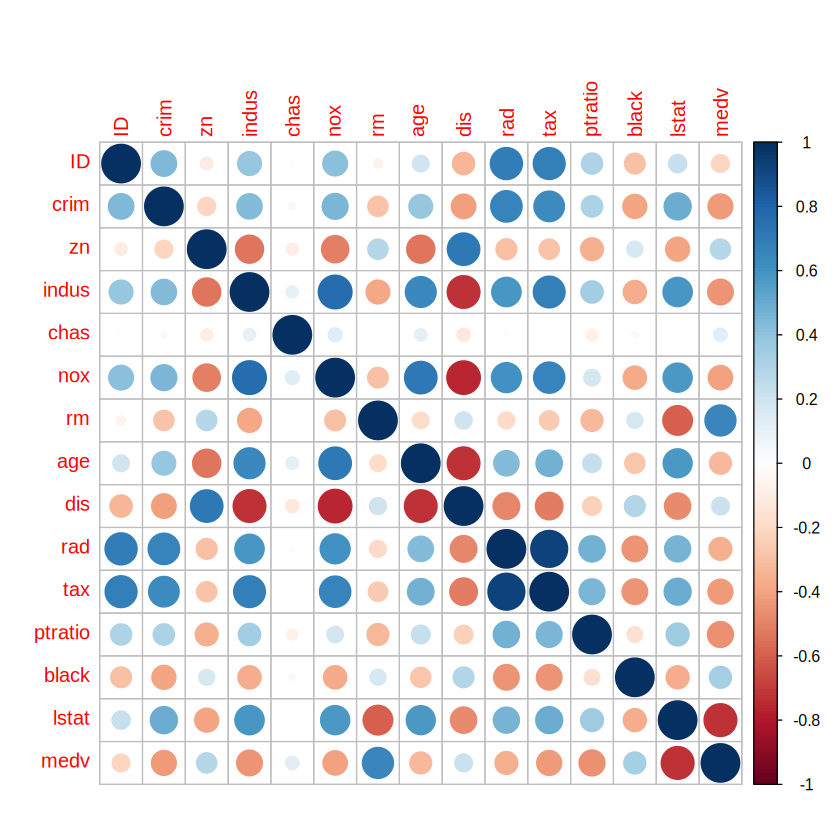

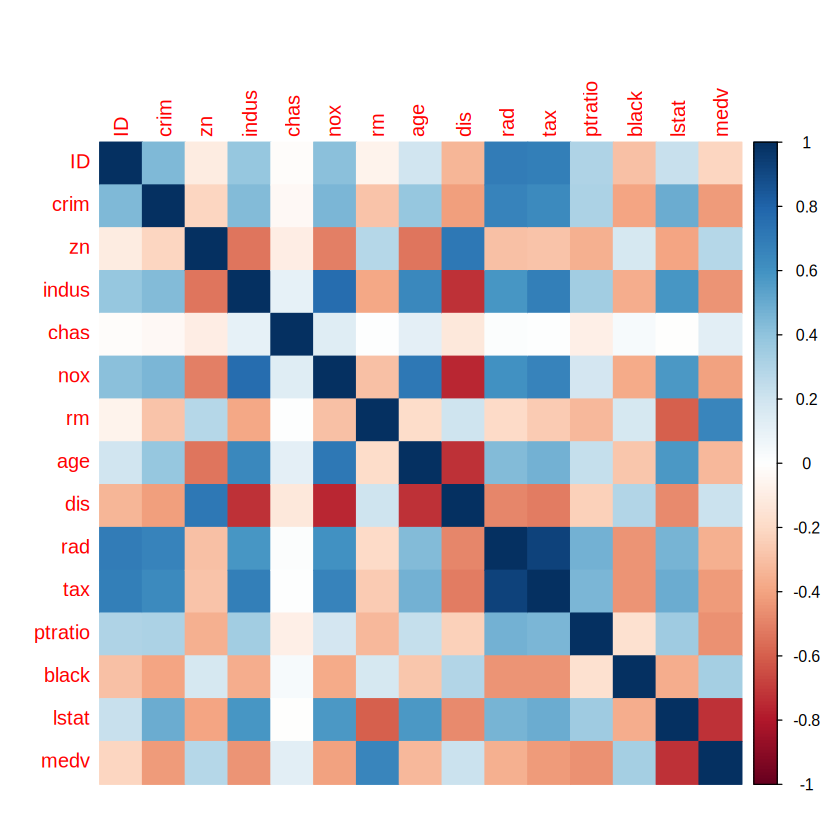

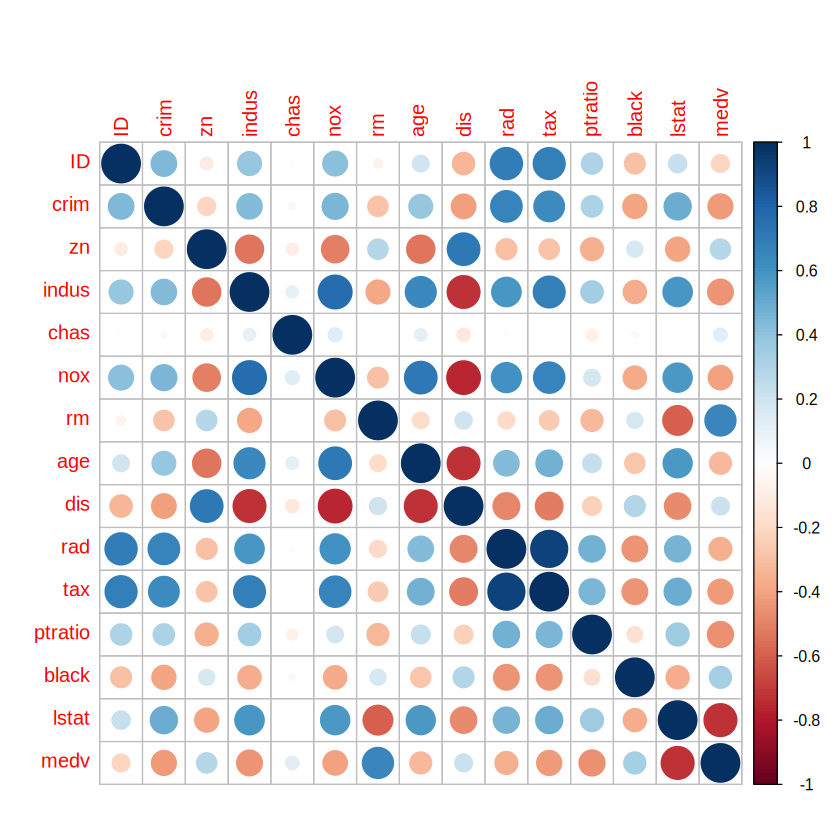

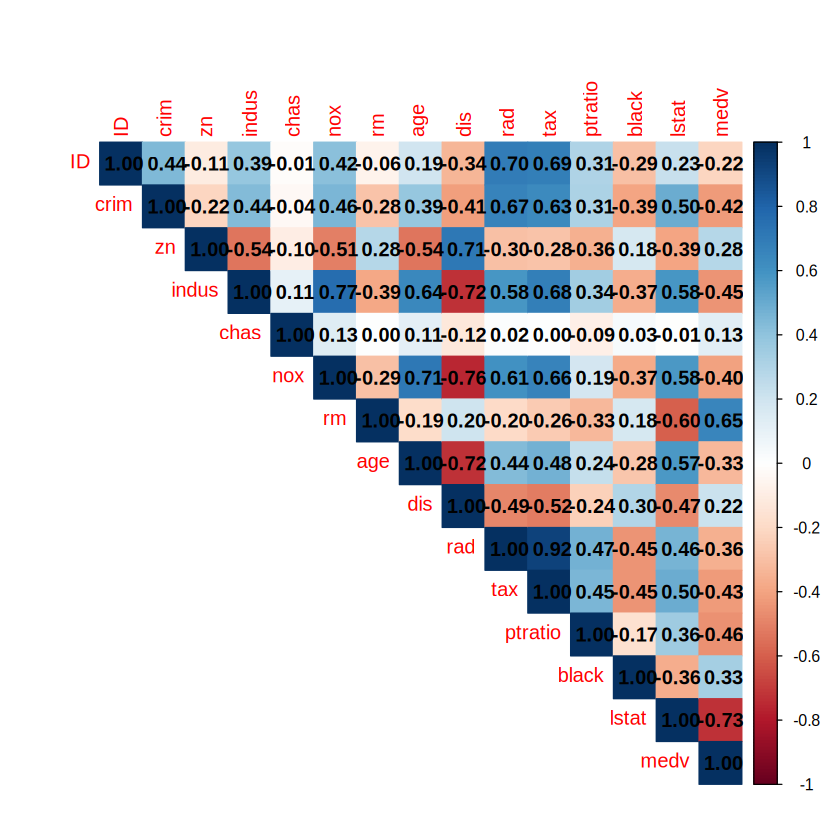

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
2,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
3,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21,28.7
4,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,395.60,12.43,22.9
5,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311,15.2,386.63,29.93,16.5
6,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311,15.2,386.71,17.10,18.9
7,0.22489,12.5,7.87,0,0.524,6.377,94.3,6.3467,5,311,15.2,392.52,20.45,15.0
8,0.11747,12.5,7.87,0,0.524,6.009,82.9,6.2267,5,311,15.2,396.90,13.27,18.9
9,0.09378,12.5,7.87,0,0.524,5.889,39.0,5.4509,5,311,15.2,390.50,15.71,21.7


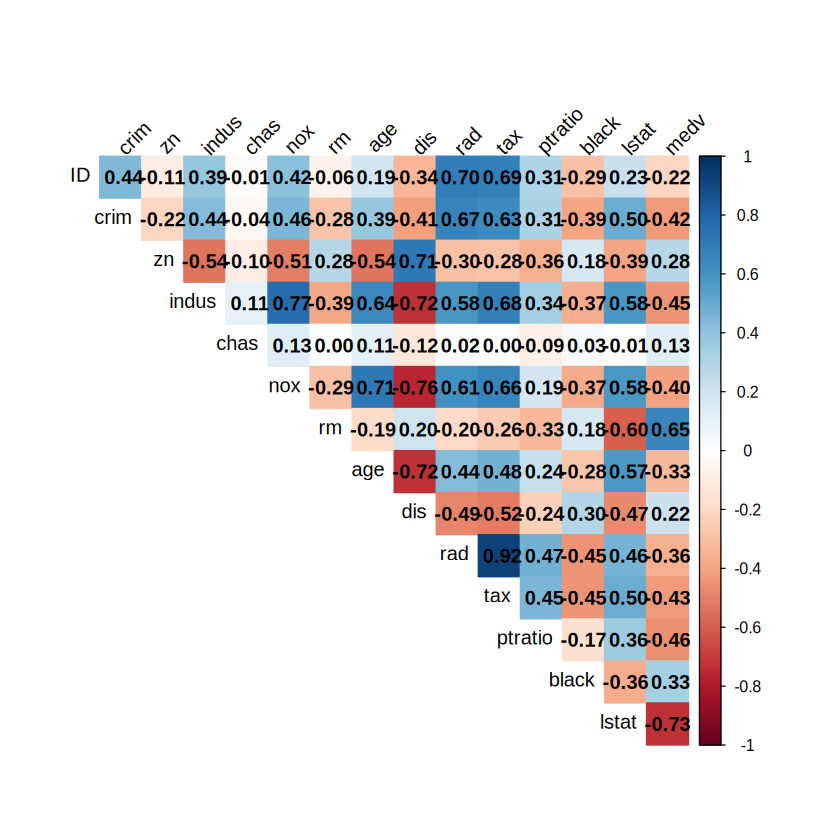

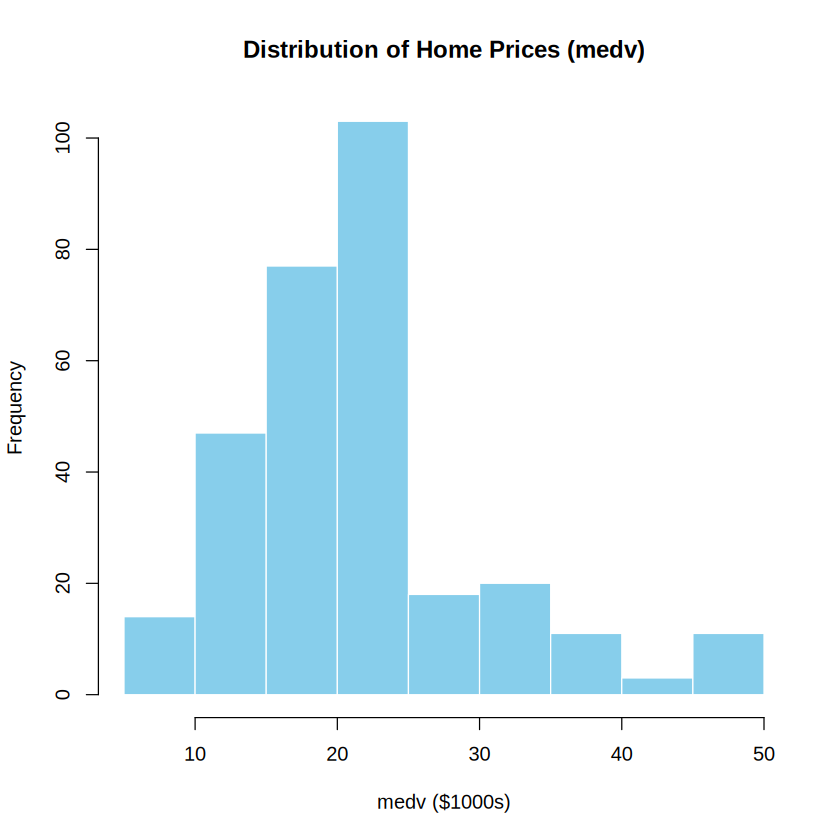

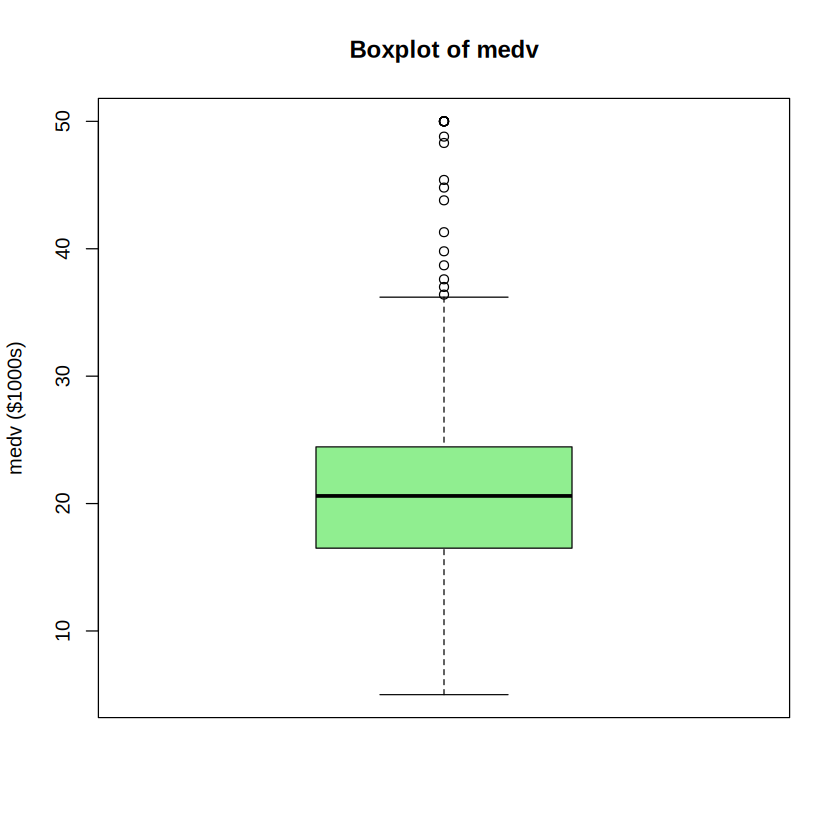

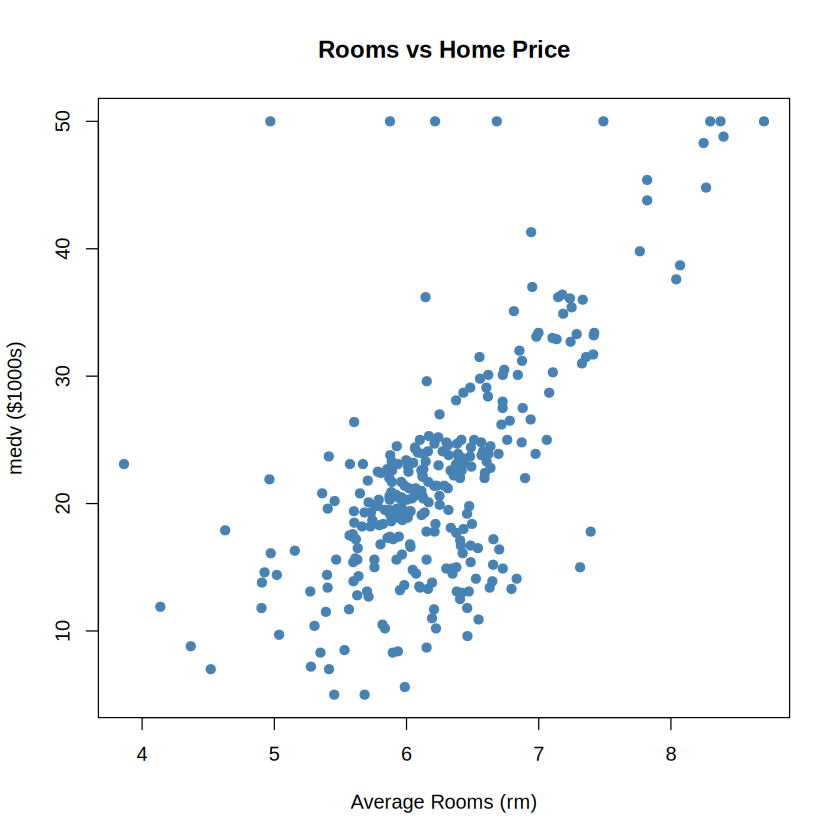

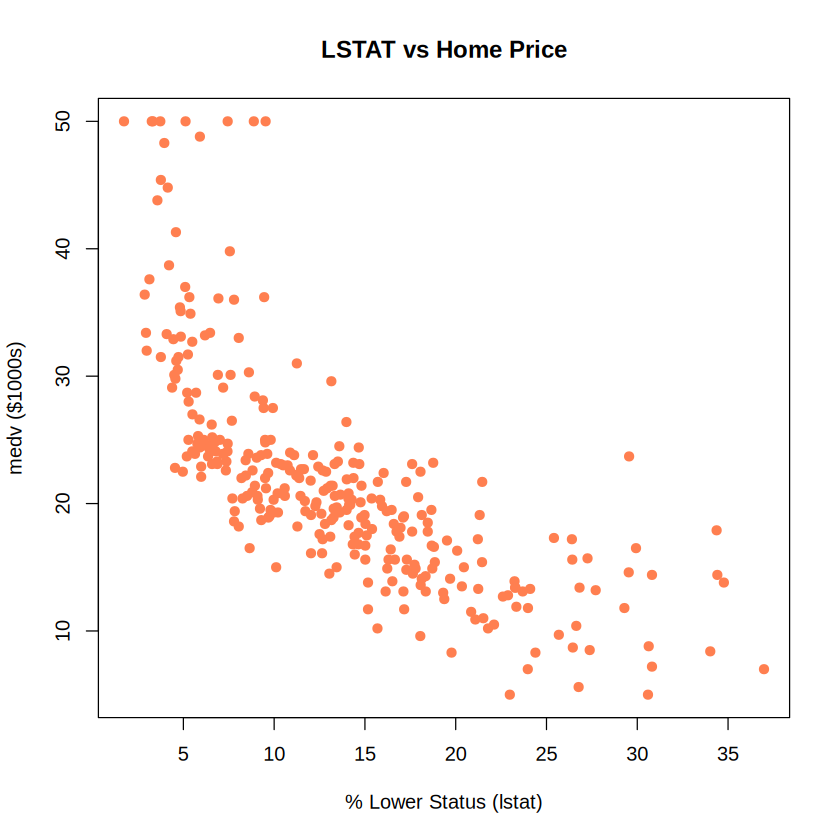

In [ ]:
corr_matrix <- cor(Boston, use = "complete.obs")
corrplot(corr_matrix)
corrplot(corr_matrix, method = "color")
corrplot(corr_matrix, method = "circle")
corrplot(corr_matrix, method = "color",addCoef.col= "black",type = "upper")
corrplot(corr_matrix, method = "color",type= "upper",addCoef.col= "black",tl.col= "black",tl.srt =45,diag = FALSE)
Boston_clean <- subset(Boston, select = -ID)
Boston_clean
hist(Boston_clean$medv, main = "Distribution of Home Prices (medv)", xlab = "medv ($1000s)", col = "skyblue", border = "white")
boxplot(Boston_clean$medv, main = "Boxplot of medv", ylab = "medv ($1000s)", col = "lightgreen")
# Rooms vs Price (Positive relationship)
plot(Boston_clean$rm, Boston_clean$medv, main = "Rooms vs Home Price", xlab = "Average Rooms (rm)", ylab = "medv ($1000s)", pch = 19, col = "steelblue")

# Lower Status % vs Price (Curved/non-linear negative relationship)
plot(Boston_clean$lstat, Boston_clean$medv, main = "LSTAT vs Home Price", xlab = "% Lower Status (lstat)", ylab = "medv ($1000s)", pch = 19, col = "coral")




In [ ]:
lm_model <- lm(medv ~ . - rad, data = Boston_clean)
summary(lm_model)

# Predict on your test dataset (replace 'test_2_' if your test file has a different name)
test_preds_lm <- predict(lm_model, newdata = test_2_)
test_preds_lm


# Combine ID with predicted medv values
submission <- data.frame(
  ID = test_2_$ID,
  medv = test_preds_lm
)

View(submission)

# Optional: Floor unrealistic near-zero predictions at the training minimum ($5.0k)
submission$medv <- pmax(submission$medv, 5.0)

# Save to CSV
write.csv(submission, "submission_lm.csv", row.names = FALSE)


getwd()



Call:
lm(formula = medv ~ . - rad, data = Boston_clean)

Residuals:
    Min      1Q  Median      3Q     Max 
-9.7104 -2.7657 -0.6797  1.9369 26.1387 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  33.278628   6.382999   5.214 3.52e-07 ***
crim         -0.074295   0.048676  -1.526  0.12801    
zn            0.036972   0.022814   1.621  0.10618    
indus        -0.093512   0.078250  -1.195  0.23304    
chas          3.708322   1.271142   2.917  0.00381 ** 
nox         -15.431870   5.181042  -2.979  0.00314 ** 
rm            3.403048   0.567571   5.996 5.99e-09 ***
age           0.003852   0.017650   0.218  0.82739    
dis          -1.510934   0.280218  -5.392 1.44e-07 ***
tax           0.001727   0.003106   0.556  0.57872    
ptratio      -0.733014   0.170945  -4.288 2.46e-05 ***
black         0.006748   0.003442   1.960  0.05091 .  
lstat        -0.547612   0.065976  -8.300 3.94e-15 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’

ERROR: Error: object 'test_2_' not found
